# AI Cybersecurity Unit 1 Mini Project [ Khushi : 2301730308 ]

## AI-Based Phishing Email Threat Analysis and Classification

In this notebook, I complete all four tasks of my AI in Cyber Security lab assignment in sequence.

### Tasks
1. Workspace Bootstrap and Environment Setup
2. Cyber Security Threat Landscape Analysis
3. Basic Machine Learning-Based Threat Classification
4. Introduction to Deep Learning

Phishing is one of the most common cyber attacks. Attackers send fake emails that pretend to come from a trusted source so that the victim clicks a malicious link, shares a password, or downloads malware.

I use the **Phishing Email Detection** dataset from Kaggle (`Phishing_Email.csv`). Each record contains the email text (`Email Text`) and its label (`Email Type`), which is either `Safe Email` or `Phishing Email`. I convert the label into a binary target where `1 = Phishing` and `0 = Safe`.

For Task 3, I use **Random Forest**.
For Task 4, I use **MLPClassifier**, which is a basic feed-forward Artificial Neural Network available in Scikit-learn.

I keep the comments and explanations simple so I can explain each step during my lab or viva.

## Task 1 — Workspace Bootstrap and Environment Setup

I use Google Colab for this project. I install or import the basic Python libraries needed for data analysis, visualization, and machine learning.

In [1]:
# I install the main libraries required for this project.
!pip -q install numpy pandas scikit-learn matplotlib seaborn

You should consider upgrading via the '/private/tmp/claude-501/-Users-khushiyadav/39c076b6-5849-45e5-8b15-384ae1baa295/scratchpad/venv/bin/python3 -m pip install --upgrade pip' command.


In [2]:
# I import the libraries that I will use throughout the notebook.
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# I hide a harmless numpy "matmul" warning that appears on some systems.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

print("Environment setup completed successfully.")

Environment setup completed successfully.


### Load the dataset

Dataset source: https://www.kaggle.com/datasets/subhajournal/phishingemails

I load the CSV file into a Pandas DataFrame. The expected file name is `Phishing_Email.csv`.

In [3]:
# I load the phishing email dataset.
df = pd.read_csv("Phishing_Email.csv")

# The first column is only the old row index, so I remove it.
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print(df.shape)
print(df["Email Type"].value_counts(dropna=False))

(18650, 2)
Email Type
Safe Email        11322
Phishing Email     7328
Name: count, dtype: int64


## Task 2 — Cyber Security Threat Landscape Analysis

In this task, I first understand the dataset and then perform basic EDA and data cleaning. I look at the structure of the data, the class distribution, missing values, duplicate emails, and some simple phishing indicators such as links, urgent words, and email length.

In [4]:
# I display the first few records so I can understand the dataset.
display(df.head())

,Email Text,Email Type
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,the other side of * galicismos * * galicismo *...,Safe Email
2,re : equistar deal tickets are you still avail...,Safe Email
3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,software at incredibly low prices ( 86 % lower...,Phishing Email


In [5]:
# I check the data types and number of non-null values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18650 entries, 0 to 18649
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Email Text  18634 non-null  object
 1   Email Type  18650 non-null  object
dtypes: object(2)
memory usage: 291.5+ KB


In [6]:
# I check the size of the dataset and the column names.
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (18650, 2)

Column names:
['Email Text', 'Email Type']


In [7]:
# I check how many missing values are present in each column.
missing_values = df.isnull().sum().sort_values(ascending=False)

print("Total missing values:", int(missing_values.sum()))
display(missing_values.to_frame("Missing Values"))

Total missing values: 16


,Missing Values
Email Text,16
Email Type,0


In [8]:
# I check for duplicate records.
# The same email can appear more than once, so I also check duplicates on the email text only.
print("Number of fully duplicate rows   :", df.duplicated().sum())
print("Number of duplicate email texts  :", df["Email Text"].duplicated().sum())

Number of fully duplicate rows   : 1111
Number of duplicate email texts  : 1112


In [9]:
# I create a binary target column.
# 1 = Phishing Email and 0 = Safe Email.
df["label"] = (df["Email Type"] == "Phishing Email").astype(int)

print("Label distribution:")
print(df["label"].value_counts(dropna=False))

target_percent = (
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nLabel distribution in percentage:")
print(target_percent)

Label distribution:
label
0    11322
1     7328
Name: count, dtype: int64

Label distribution in percentage:
label
0    60.71
1    39.29
Name: proportion, dtype: float64


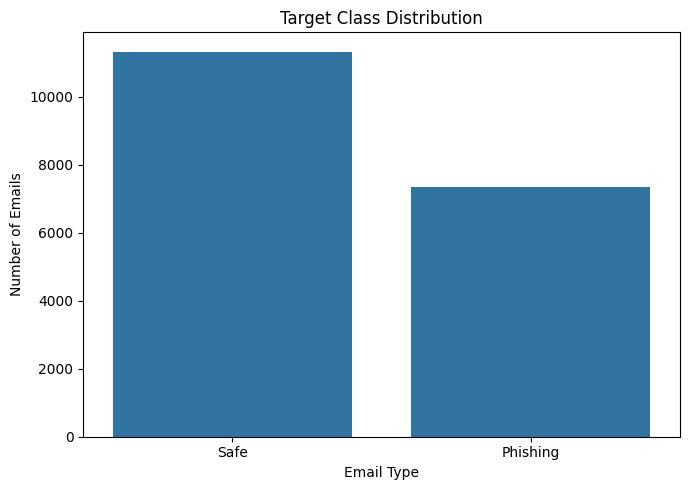

In [10]:
# I visualize the two target classes.
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Target Class Distribution")
plt.xlabel("Email Type")
plt.ylabel("Number of Emails")
plt.xticks([0, 1], ["Safe", "Phishing"])
plt.tight_layout()
plt.show()

### Phishing indicator analysis

The dataset only contains raw email text, so I create a few simple indicator features from the text. Security teams often look at these signs when they check a suspicious email:

- **email_length** — number of characters
- **word_count** — number of words
- **url_count** — number of links (`http`, `www`)
- **exclamation_count** — number of `!` characters
- **urgent_word_count** — words such as *urgent, verify, account, password, click, bank*
- **money_word_count** — words such as *free, money, offer, win, $*

I use these features only for analysis in Task 2. The models in Task 3 and Task 4 learn directly from the email text.

In [11]:
# I fill missing email text with an empty string so the text functions work.
df["Email Text"] = df["Email Text"].fillna("").astype(str)

urgent_words = r"\b(urgent|immediately|verify|account|password|login|click|bank|suspend|confirm|security|update)\b"
money_words = r"(\$|\bfree\b|\bmoney\b|\boffer\b|\bwin\b|\bwinner\b|\bprize\b|\bcash\b|\bcredit\b)"

text_lower = df["Email Text"].str.lower()

df["email_length"] = df["Email Text"].str.len()
df["word_count"] = df["Email Text"].str.split().str.len()
df["url_count"] = text_lower.str.count(r"http|www\.")
df["exclamation_count"] = df["Email Text"].str.count("!")
df["urgent_word_count"] = text_lower.str.count(urgent_words)
df["money_word_count"] = text_lower.str.count(money_words)

indicator_features = [
    "email_length",
    "word_count",
    "url_count",
    "exclamation_count",
    "urgent_word_count",
    "money_word_count"
]

display(df[indicator_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
email_length,18650.0,2753.289920,124814.106957,0.0,403.0,880.0,1879.75,17036692.0
word_count,18650.0,534.720429,25839.565579,0.0,74.0,159.0,354.00,3527576.0
url_count,18650.0,1.563271,43.934458,0.0,0.0,0.0,1.00,4637.0
exclamation_count,18650.0,2.438445,105.419298,0.0,0.0,0.0,1.00,14368.0
urgent_word_count,18650.0,0.838070,18.591140,0.0,0.0,0.0,1.00,2522.0
money_word_count,18650.0,3.304879,127.814416,0.0,0.0,0.0,1.00,17394.0


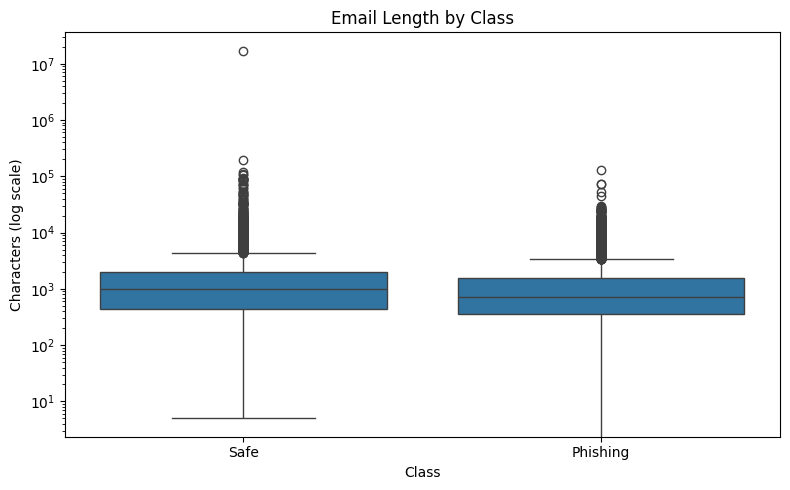

In [12]:
# I compare the email length of safe and phishing emails.
# I use a log scale because a few emails are extremely long.
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="label",
    y="email_length"
)
plt.yscale("log")
plt.title("Email Length by Class")
plt.xlabel("Class")
plt.ylabel("Characters (log scale)")
plt.xticks([0, 1], ["Safe", "Phishing"])
plt.tight_layout()
plt.show()

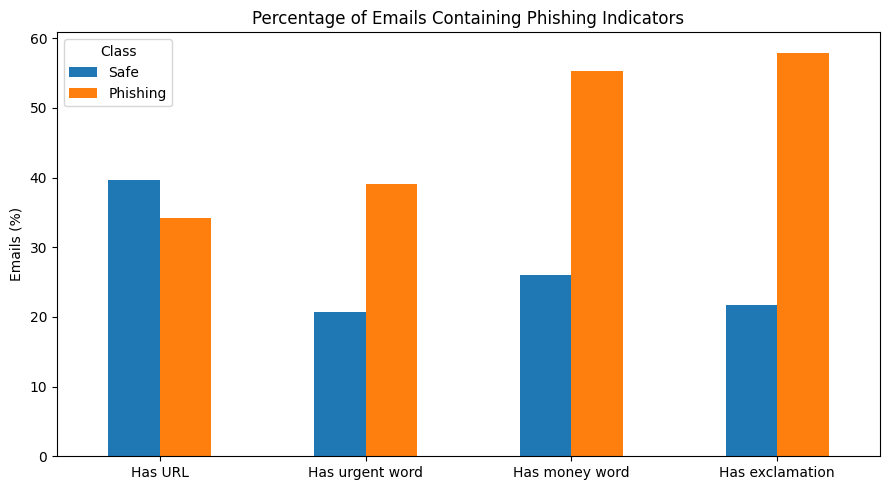

,Has URL,Has urgent word,Has money word,Has exclamation
label,,,,
Safe,39.60,20.71,25.98,21.75
Phishing,34.25,39.10,55.34,57.94


In [13]:
# I compare the percentage of emails that contain at least one link,
# urgent word, money word, or exclamation mark.
contains_summary = pd.DataFrame({
    "Has URL": df["url_count"] > 0,
    "Has urgent word": df["urgent_word_count"] > 0,
    "Has money word": df["money_word_count"] > 0,
    "Has exclamation": df["exclamation_count"] > 0,
    "label": df["label"]
}).groupby("label").mean().mul(100).rename(index={0: "Safe", 1: "Phishing"})

contains_summary.T.plot(kind="bar", figsize=(9, 5))
plt.title("Percentage of Emails Containing Phishing Indicators")
plt.ylabel("Emails (%)")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

display(contains_summary.round(2))

In [14]:
# I compare the class-wise average of all indicator features.
indicator_summary = (
    df.groupby("label")[indicator_features]
    .mean()
    .rename(index={0: "Safe", 1: "Phishing"})
)

display(indicator_summary.round(2))

,email_length,word_count,url_count,exclamation_count,urgent_word_count,money_word_count
label,,,,,,
Safe,3493.01,685.87,2.01,1.89,0.69,2.85
Phishing,1610.40,301.19,0.87,3.29,1.06,4.00


### Data cleaning

I clean the data before model training. I remove rows with missing or empty email text, remove duplicate emails, and make sure the target is stored as an integer.

Removing duplicate email texts is important. If the same email appears in both the training and testing data, the model can simply remember it, and the test score will look better than it really is (data leakage).

In [15]:
# I remove rows where the email text was missing or is empty.
before_empty = len(df)

df = df[df["Email Text"].str.strip() != ""]
df = df[df["Email Text"].str.strip().str.lower() != "empty"]

print("Rows before removing empty emails:", before_empty)
print("Rows after removing empty emails :", len(df))

Rows before removing empty emails: 18650
Rows after removing empty emails : 18098


In [16]:
# I remove duplicate emails based on the email text.
before_duplicates = len(df)

df = df.drop_duplicates(subset=["Email Text"]).reset_index(drop=True)

after_duplicates = len(df)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates :", after_duplicates)
print("Duplicates removed              :", before_duplicates - after_duplicates)

Rows before removing duplicates: 18098
Rows after removing duplicates : 17535
Duplicates removed              : 563


In [17]:
# I make sure the target is stored as an integer.
df["label"] = df["label"].astype(int)

print("Target values after cleaning:")
print(df["label"].value_counts())

print("\nData cleaning completed.")
print("Final dataset shape:", df.shape)

Target values after cleaning:
label
0    10979
1     6556
Name: count, dtype: int64

Data cleaning completed.
Final dataset shape: (17535, 9)


### My observation from Task 2

From the EDA, I can see that the dataset has more safe emails than phishing emails, but both classes have enough examples for training. Phishing emails much more often contain urgent words, money-related words, and exclamation marks. These match common social-engineering tricks such as fake offers, fake account warnings, and pressure on the victim to act quickly. Interestingly, links alone are not a strong sign, because many safe emails (for example mailing lists) also contain links.

I also found and removed missing and duplicate emails before model training, so the test results are more reliable.

For the classification stage, I use the email text because it directly contains the content that an attacker writes.

## Task 3 — Basic Machine Learning-Based Threat Classification

I use **Random Forest** as my traditional machine-learning model.

I split the cleaned data into 80% training and 20% testing. I use a stratified split so that both sets keep the same ratio of safe and phishing emails.

I convert the email text into TF-IDF features and then reduce the feature size using TruncatedSVD before training Random Forest.

In [18]:
from sklearn.model_selection import train_test_split

# I split the emails into training and testing sets.
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

train_text = train_df["Email Text"]
test_text = test_df["Email Text"]

y_train = train_df["label"]
y_test = test_df["label"]

print("Training rows:", len(train_df))
print("Testing rows :", len(test_df))

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training rows: 14028
Testing rows : 3507

Training target:
label
0    8783
1    5245
Name: count, dtype: int64

Testing target:
label
0    2196
1    1311
Name: count, dtype: int64


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

# I convert the email text into numerical TF-IDF features.
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3,
    sublinear_tf=True,
    stop_words="english"
)

# I fit TF-IDF only on training text.
# The testing text is transformed using the already fitted vectorizer.
X_train_tfidf = tfidf.fit_transform(train_text)
X_test_tfidf = tfidf.transform(test_text)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape :", X_test_tfidf.shape)

TF-IDF training shape: (14028, 5000)
TF-IDF testing shape : (3507, 5000)


In [20]:
from sklearn.decomposition import TruncatedSVD

# I reduce the 5000 TF-IDF features to 100 components.
# This makes the data smaller and easier for the models to process.
svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

print("SVD training shape:", X_train_svd.shape)
print("SVD testing shape :", X_test_svd.shape)

print(
    "Explained variance:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

SVD training shape: (14028, 100)
SVD testing shape : (3507, 100)
Explained variance: 0.2579


In [21]:
from sklearn.ensemble import RandomForestClassifier

# I train my Random Forest classifier.
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_start = time.time()

rf_model.fit(X_train_svd, y_train)

rf_train_time = time.time() - rf_start

print(
    "Random Forest training completed in",
    round(rf_train_time, 2),
    "seconds."
)

print("Classes learned by Random Forest:", rf_model.classes_)

Random Forest training completed in 5.15 seconds.
Classes learned by Random Forest: [0 1]


In [22]:
# I use the trained Random Forest to predict the unseen test data.
rf_pred = rf_model.predict(X_test_svd)

# I get the probability of class 1 (phishing) for ROC-AUC.
rf_prob = rf_model.predict_proba(X_test_svd)[:, 1]

print("Random Forest prediction completed.")

Random Forest prediction completed.


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_auc = roc_auc_score(y_test, rf_prob)
rf_pr_auc = average_precision_score(y_test, rf_prob)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_auc:.4f}")
print(f"PR-AUC   : {rf_pr_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Safe", "Phishing"],
        zero_division=0
    )
)

Random Forest Results
---------------------
Accuracy : 0.9735
Precision: 0.9642
Recall   : 0.9649
F1-score : 0.9645
ROC-AUC  : 0.9961
PR-AUC   : 0.9937

Classification Report:
              precision    recall  f1-score   support

        Safe       0.98      0.98      0.98      2196
    Phishing       0.96      0.96      0.96      1311

    accuracy                           0.97      3507
   macro avg       0.97      0.97      0.97      3507
weighted avg       0.97      0.97      0.97      3507



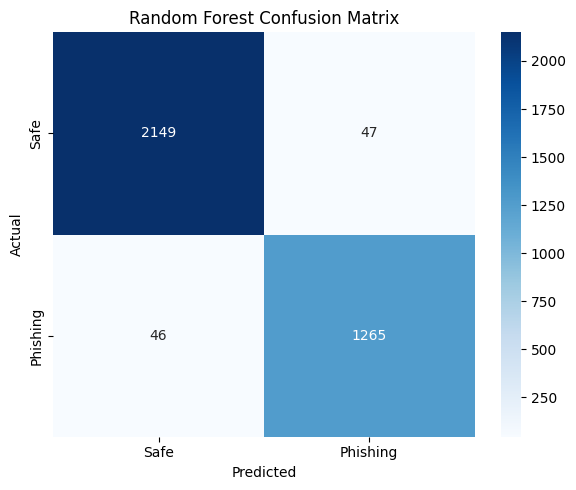

Phishing emails missed by Random Forest (false negatives): 46
Safe emails wrongly flagged (false positives)            : 47


In [24]:
# I visualize the Random Forest confusion matrix.
rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Safe", "Phishing"],
    yticklabels=["Safe", "Phishing"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

# In cyber security, a false negative is the most dangerous mistake,
# because a phishing email reaches the user as if it were safe.
print("Phishing emails missed by Random Forest (false negatives):", rf_cm[1, 0])
print("Safe emails wrongly flagged (false positives)            :", rf_cm[0, 1])

## Task 4 — Introduction to Deep Learning

For the deep-learning part, I use **MLPClassifier** from Scikit-learn.

MLP stands for Multi-Layer Perceptron. It is a basic feed-forward neural network, so it satisfies the lab requirement for a basic neural-network model.

I use the same TF-IDF/SVD representation and the same train/test data as Random Forest. Before training the MLP, I scale the features because neural networks generally work better when numerical inputs are on a similar scale.

In [25]:
from sklearn.preprocessing import StandardScaler

# I use the same SVD features for my neural network and scale them.
scaler = StandardScaler()

X_train_mlp = scaler.fit_transform(X_train_svd)
X_test_mlp = scaler.transform(X_test_svd)

print("MLP training shape:", X_train_mlp.shape)
print("MLP testing shape :", X_test_mlp.shape)

MLP training shape: (14028, 100)
MLP testing shape : (3507, 100)


In [26]:
from sklearn.neural_network import MLPClassifier

# I use a simple MLP with two hidden layers.
# This is the basic neural-network model.
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    batch_size=128,
    learning_rate_init=0.001,
    alpha=0.001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.20,
    n_iter_no_change=5,
    random_state=42
)

mlp_start = time.time()

mlp_model.fit(X_train_mlp, y_train)

mlp_train_time = time.time() - mlp_start

print(
    "MLPClassifier training completed in",
    round(mlp_train_time, 2),
    "seconds."
)

print("Iterations used:", mlp_model.n_iter_)
print("Classes learned by MLP:", mlp_model.classes_)

MLPClassifier training completed in 0.31 seconds.
Iterations used: 17
Classes learned by MLP: [0 1]


In [27]:
# I generate predictions from my trained MLP.
mlp_pred = mlp_model.predict(X_test_mlp)
mlp_prob = mlp_model.predict_proba(X_test_mlp)[:, 1]

print("MLP prediction completed.")

MLP prediction completed.


In [28]:
mlp_accuracy = accuracy_score(y_test, mlp_pred)
mlp_precision = precision_score(y_test, mlp_pred, zero_division=0)
mlp_recall = recall_score(y_test, mlp_pred, zero_division=0)
mlp_f1 = f1_score(y_test, mlp_pred, zero_division=0)
mlp_auc = roc_auc_score(y_test, mlp_prob)
mlp_pr_auc = average_precision_score(y_test, mlp_prob)

print("MLPClassifier Results")
print("---------------------")
print(f"Accuracy : {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall   : {mlp_recall:.4f}")
print(f"F1-score : {mlp_f1:.4f}")
print(f"ROC-AUC  : {mlp_auc:.4f}")
print(f"PR-AUC   : {mlp_pr_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        mlp_pred,
        target_names=["Safe", "Phishing"],
        zero_division=0
    )
)

MLPClassifier Results
---------------------
Accuracy : 0.9786
Precision: 0.9647
Recall   : 0.9786
F1-score : 0.9716
ROC-AUC  : 0.9967
PR-AUC   : 0.9951

Classification Report:
              precision    recall  f1-score   support

        Safe       0.99      0.98      0.98      2196
    Phishing       0.96      0.98      0.97      1311

    accuracy                           0.98      3507
   macro avg       0.98      0.98      0.98      3507
weighted avg       0.98      0.98      0.98      3507



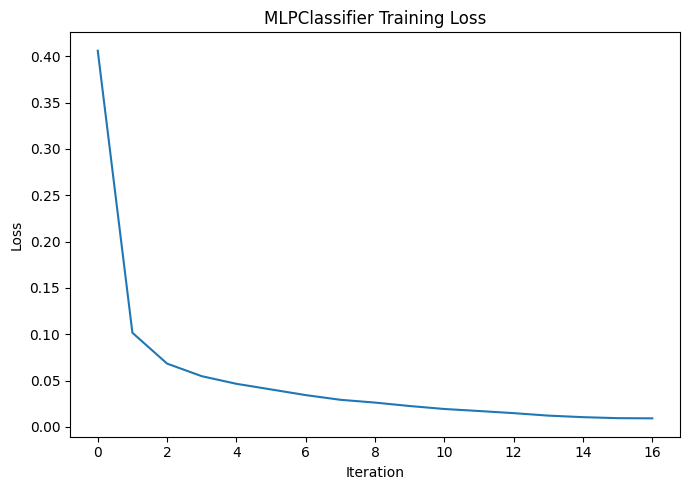

In [29]:
# I plot the training loss to see how the MLP learned over the iterations.
plt.figure(figsize=(7, 5))

plt.plot(mlp_model.loss_curve_)

plt.title("MLPClassifier Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

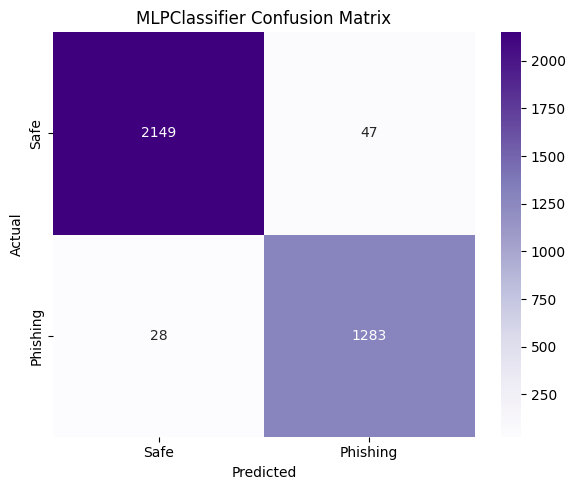

Phishing emails missed by MLP (false negatives): 28
Safe emails wrongly flagged (false positives)  : 47


In [30]:
# I visualize the MLP confusion matrix.
mlp_cm = confusion_matrix(y_test, mlp_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    mlp_cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Safe", "Phishing"],
    yticklabels=["Safe", "Phishing"]
)

plt.title("MLPClassifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

print("Phishing emails missed by MLP (false negatives):", mlp_cm[1, 0])
print("Safe emails wrongly flagged (false positives)  :", mlp_cm[0, 1])

## Model Comparison

I now compare Random Forest and MLPClassifier using the same test data and the same reduced TF-IDF representation. This makes the comparison easier to understand because both models receive the same type of input.

In [31]:
# I compare the two models using the same test dataset.
comparison = pd.DataFrame({
    "Model": ["Random Forest", "MLPClassifier"],
    "Accuracy": [rf_accuracy, mlp_accuracy],
    "Precision": [rf_precision, mlp_precision],
    "Recall": [rf_recall, mlp_recall],
    "F1-Score": [rf_f1, mlp_f1],
    "ROC-AUC": [rf_auc, mlp_auc],
    "PR-AUC": [rf_pr_auc, mlp_pr_auc],
    "Missed Phishing (FN)": [rf_cm[1, 0], mlp_cm[1, 0]],
    "Training Time (sec)": [rf_train_time, mlp_train_time]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Missed Phishing (FN),Training Time (sec)
0,Random Forest,0.9735,0.9642,0.9649,0.9645,0.9961,0.9937,46,5.1514
1,MLPClassifier,0.9786,0.9647,0.9786,0.9716,0.9967,0.9951,28,0.3136


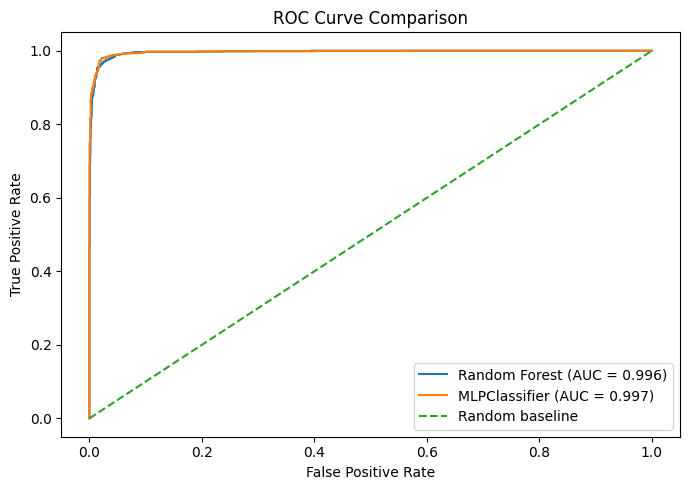

In [32]:
from sklearn.metrics import roc_curve

# I compare the ROC curves of both models.
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
mlp_fpr, mlp_tpr, _ = roc_curve(y_test, mlp_prob)

plt.figure(figsize=(7, 5))

plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot(mlp_fpr, mlp_tpr, label=f"MLPClassifier (AUC = {mlp_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()
plt.show()

In [33]:
# I test both models on a few new example emails that are not in the dataset.
sample_emails = [
    "Dear customer, your bank account has been suspended. Click here immediately to verify your password and login details.",
    "Congratulations! You are the lucky winner of a free $1000 gift card. Claim your prize now!!!",
    "Hi team, the project meeting is moved to Thursday at 3 pm. Please bring the updated report.",
    "Thanks for sending the lecture notes. I will review chapter 4 before the exam next week."
]

sample_svd = svd.transform(tfidf.transform(sample_emails))
sample_rf = rf_model.predict(sample_svd)
sample_mlp = mlp_model.predict(scaler.transform(sample_svd))

label_name = {0: "Safe", 1: "Phishing"}

display(pd.DataFrame({
    "Email": sample_emails,
    "Random Forest": [label_name[p] for p in sample_rf],
    "MLPClassifier": [label_name[p] for p in sample_mlp]
}))

,Email,Random Forest,MLPClassifier
0,"Dear customer, your bank account has been susp...",Phishing,Phishing
1,Congratulations! You are the lucky winner of a...,Phishing,Phishing
2,"Hi team, the project meeting is moved to Thurs...",Safe,Safe
3,Thanks for sending the lecture notes. I will r...,Safe,Safe


## My Conclusion

In this mini-project, I completed all four tasks in sequence on a phishing email dataset.

For Task 1, I prepared the Colab environment and loaded the Kaggle Phishing Email dataset.

For Task 2, I performed EDA and data cleaning. I checked the dataset structure, class distribution, missing values, and duplicate emails. I also created simple phishing indicators such as links, urgent words, money words, and exclamation marks, and compared them between safe and phishing emails.

For Task 3, I used Random Forest for the machine-learning classification task. I converted email text into TF-IDF features and reduced the feature size using TruncatedSVD.

For Task 4, I used MLPClassifier as my basic deep-learning model. I used the same processed features and the same train/test split so that the comparison is fair.

Finally, I compared both models using accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, confusion matrices, missed phishing emails, and training time. In cyber security, recall on the phishing class is especially important, because every missed phishing email is a possible attack that reaches the user.